# TV5 – Công việc 1.5: Khám phá lớp không giám sát (Class Discovery - H5)

**Thành viên:** TV5  
**Giai đoạn:** 1 (Hiểu dữ liệu) · **Thời hạn bàn giao:** Chủ nhật 01/11  
**Mã công việc:** 1.5 (Kế hoạch mục 3.2, 5.2)

---

## Giả thuyết nghiên cứu H5

> **H5:** *Dữ liệu biểu hiện gen có cấu trúc cụm tự nhiên trùng khớp với phân loại lâm sàng ALL/AML và các phân nhóm subtype (B-ALL, T-ALL) mà không cần dùng nhãn lâm sàng.*

### Mục tiêu phân tích:
1. Tái lập ý tưởng Class Discovery kinh điển của Golub et al. (Science, 1999) bằng các phương pháp học không giám sát: **K-Means**, **Hierarchical Clustering** (khoảng cách 1 - Pearson correlation, liên kết average, complete, ward), và **Self-Organizing Maps (SOM)** qua thư viện `minisom`.
2. Kiểm tra độ ổn định qua 10 random seeds và định lượng chất lượng phân cụm bằng **Adjusted Rand Index (ARI)** và **Silhouette Score**.
3. Đối chiếu chặt chẽ với kết quả bài báo gốc: SOM 2 cụm có 24/25 ALL ở cụm A1 và 10/13 AML ở cụm A2.
4. Trực quan hóa **Hình F05** (Clustermap 2 chiều), **Hình F05b** (So sánh cụm trên PCA), và **Hình F05c** (Phân bố mẫu trên nút SOM).


In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# Thiết lập đường dẫn gốc dự án
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.decomposition import PCA
from minisom import MiniSom

from src.config import (
    CURATED_DIR, REPORT_FIG_DIR, SLIDE_FIG_DIR, METRICS_DIR,
    PALETTE, RANDOM_SEED, RESULTS_DIR
)
from src.load import load_golub

print("Môi trường sẵn sàng. Thư mục gốc:", ROOT)


Môi trường sẵn sàng. Thư mục gốc: C:\Users\pinkc\2026.1\Golub-project


## 1. Nạp dữ liệu và kiểm tra đầu vào

Chúng ta sử dụng ma trận biểu hiện gen đã tiền xử lý ở tầng `curated`:
- `X_log10_filtered`: 72 x 3571 gen sau khi lọc biến thiên theo tiêu chí Dudoit et al. (tỷ lệ max/min >= 5, chênh lệch >= 500 trên thang gốc).
- `samples`: Metadata lâm sàng gồm 72 mẫu bệnh nhân với các cột `class`, `subtype`, `split`, `tissue`, `source`.


In [2]:
# Đọc dữ liệu từ tầng curated
X_log10, samples = load_golub("curated")
X_filtered = pd.read_parquet(CURATED_DIR / "X_log10_filtered.parquet")

print(f"Kích thước X_log10 (toàn bộ probe): {X_log10.shape}")
print(f"Kích thước X_filtered (đã lọc biến thiên): {X_filtered.shape}")
print(f"Số lượng mẫu metadata: {len(samples)}")

# Thống kê phân bố nhãn
display(pd.crosstab(samples["split"], samples["class"], margins=True))
display(pd.crosstab(samples["class"], samples["subtype"], margins=True))


Kích thước X_log10 (toàn bộ probe): (72, 7129)
Kích thước X_filtered (đã lọc biến thiên): (72, 3571)
Số lượng mẫu metadata: 72


class,ALL,AML,All
split,,,
test,20,14,34
train,27,11,38
All,47,25,72


subtype,AML,B-ALL,T-ALL,All
class,,,,
ALL,0,38,9,47
AML,25,0,0,25
All,25,38,9,72


## 2. Phân cụm K-Means

Thực nghiệm K-Means trên 10 random seeds khác nhau để đo lường độ ổn định (stability) và chất lượng phân cụm:
- Với k = 2: So sánh cụm với nhãn chính `class` (ALL vs AML).
- Với k = 4: So sánh cụm với phân nhóm `subtype` (B-ALL, T-ALL, AML).


In [3]:
# 2.1 K-Means k=2 (ALL vs AML)
kmeans_k2_ari = []
kmeans_k2_sil = []

for seed in range(10):
    km = KMeans(n_clusters=2, random_state=seed, n_init=10)
    labels = km.fit_predict(X_filtered)
    kmeans_k2_ari.append(adjusted_rand_score(samples["class"], labels))
    kmeans_k2_sil.append(silhouette_score(X_filtered, labels))

print("=== K-Means (k = 2) qua 10 seeds ===")
print(f"ARI vs class:       {np.mean(kmeans_k2_ari):.4f} +/- {np.std(kmeans_k2_ari):.4f}")
print(f"Silhouette Score:   {np.mean(kmeans_k2_sil):.4f} +/- {np.std(kmeans_k2_sil):.4f}")

# Khớp mô hình mẫu với seed 42 để lập bảng chéo
km2 = KMeans(n_clusters=2, random_state=42, n_init=20).fit(X_filtered)
crosstab_km2 = pd.crosstab(pd.Series(km2.labels_, name="Cụm K-Means"), samples["class"])
print("\nBảng chéo K-Means k=2 vs Nhãn lâm sàng:")
display(crosstab_km2)


  File "D:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\anaconda\Lib\subprocess.py", line 1554, in _execute_child
    hp, ht, pid, t

=== K-Means (k = 2) qua 10 seeds ===
ARI vs class:       0.9386 +/- 0.0163
Silhouette Score:   0.0954 +/- 0.0005

Bảng chéo K-Means k=2 vs Nhãn lâm sàng:


class,ALL,AML
Cụm K-Means,,
0,4,20
1,42,5


In [4]:
# 2.2 K-Means k=4 (Subtype: B-ALL, T-ALL, AML)
kmeans_k4_ari = []
kmeans_k4_sil = []

for seed in range(10):
    km = KMeans(n_clusters=4, random_state=seed, n_init=10)
    labels = km.fit_predict(X_filtered)
    kmeans_k4_ari.append(adjusted_rand_score(samples["subtype"], labels))
    kmeans_k4_sil.append(silhouette_score(X_filtered, labels))

print("=== K-Means (k = 4) qua 10 seeds ===")
print(f"ARI vs subtype:     {np.mean(kmeans_k4_ari):.4f} +/- {np.std(kmeans_k4_ari):.4f}")
print(f"Silhouette Score:   {np.mean(kmeans_k4_sil):.4f} +/- {np.std(kmeans_k4_sil):.4f}")

km4 = KMeans(n_clusters=4, random_state=42, n_init=20).fit(X_filtered)
crosstab_km4 = pd.crosstab(pd.Series(km4.labels_, name="Cụm K-Means"), samples["subtype"])
print("\nBảng chéo K-Means k=4 vs Subtype:")
display(crosstab_km4)


=== K-Means (k = 4) qua 10 seeds ===
ARI vs subtype:     0.4260 +/- 0.1074
Silhouette Score:   0.0776 +/- 0.0045

Bảng chéo K-Means k=4 vs Subtype:


subtype,AML,B-ALL,T-ALL
Cụm K-Means,,,
0,5,18,1
1,20,4,0
2,0,6,5
3,0,9,3


## 3. Phân cụm phân cấp (Hierarchical Clustering)

Theo yêu cầu của đề tài, chúng ta khảo sát phân cụm phân cấp với:
- Khoảng cách: 1 - Pearson correlation (phù hợp với bản chất dữ liệu biểu hiện gen microarray).
- Phương pháp liên kết: `average linkage` (chuẩn bài báo Golub 1999).
- Đối chiếu mở rộng: Thử nghiệm `complete linkage` và `ward linkage` để kiểm tra tính bền vững trước mẫu ngoại lai.


In [5]:
# Tính ma trận khoảng cách tương quan Pearson giữa 72 mẫu
dist_corr = squareform(pdist(X_filtered.values, metric="correlation"))

# 3.1 Thử nghiệm các phương pháp liên kết
linkage_methods = ["average", "complete", "single"]
hier_results = []

for link in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage=link)
    labels = hc.fit_predict(dist_corr)
    ari = adjusted_rand_score(samples["class"], labels)
    sil = silhouette_score(dist_corr, labels, metric="precomputed")
    hier_results.append({"Linkage": link, "ARI vs class": round(ari, 4), "Silhouette": round(sil, 4)})

# Thêm Ward linkage trên không gian Euclid
hc_ward = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_filtered)
ari_ward = adjusted_rand_score(samples["class"], hc_ward.labels_)
sil_ward = silhouette_score(X_filtered, hc_ward.labels_)
hier_results.append({"Linkage": "ward (Euclid)", "ARI vs class": round(ari_ward, 4), "Silhouette": round(sil_ward, 4)})

display(pd.DataFrame(hier_results))

# Chi tiết bảng chéo của average linkage vs complete linkage
hc_avg = AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage="average").fit(dist_corr)
hc_comp = AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage="complete").fit(dist_corr)

print("Bảng chéo Hierarchical (average linkage, k=2):")
display(pd.crosstab(pd.Series(hc_avg.labels_, name="Cluster HC-Average"), samples["class"]))

print("Bảng chéo Hierarchical (complete linkage, k=2):")
display(pd.crosstab(pd.Series(hc_comp.labels_, name="Cluster HC-Complete"), samples["class"]))


,Linkage,ARI vs class,Silhouette
0,average,-0.0129,0.2822
1,complete,0.6900,0.1483
2,single,-0.0129,0.2822
3,ward (Euclid),0.6889,0.0778


Bảng chéo Hierarchical (average linkage, k=2):


class,ALL,AML
Cluster HC-Average,,
0,45,25
1,1,0


Bảng chéo Hierarchical (complete linkage, k=2):


class,ALL,AML
Cluster HC-Complete,,
0,8,23
1,38,2


## 4. Tái lập mô hình Self-Organizing Map (SOM) của Golub 1999

Bài báo gốc của Golub et al. (Science 1999) sử dụng thuật toán SOM để khám phá lớp:
- **Tập Train ban đầu (38 mẫu):** Báo cáo SOM 2 cụm có **24/25** mẫu ALL nằm trong cụm A1, và **10/13** mẫu AML nằm trong cụm A2.
- **Toàn bộ dữ liệu (72 mẫu):** Kiểm tra khả năng tổng quát hóa của SOM khi có thêm mẫu ngoại vi PB và các ca AML trẻ em.


In [6]:
# 4.1 SOM trên tập Train 38 mẫu (đối chiếu trực tiếp với bài báo Golub)
train_mask = samples["split"] == "train"
X_tr = X_filtered[train_mask]
y_tr = samples.loc[train_mask, "class"]

som_tr = MiniSom(1, 2, X_tr.shape[1], sigma=0.5, learning_rate=0.5, random_seed=42)
som_tr.random_weights_init(X_tr.values)
som_tr.train_random(X_tr.values, 1000)

win_tr = [som_tr.winner(x)[1] for x in X_tr.values]
ct_som_tr = pd.crosstab(pd.Series(win_tr, name="Nút SOM (1x2)"), y_tr)
print("=== Bảng chéo SOM trên 38 mẫu Train (Tái lập Golub 1999) ===")
display(ct_som_tr)

# 4.2 SOM trên toàn bộ 72 mẫu
som_all = MiniSom(1, 2, X_filtered.shape[1], sigma=0.5, learning_rate=0.5, random_seed=42)
som_all.random_weights_init(X_filtered.values)
som_all.train_random(X_filtered.values, 1500)

win_all = [som_all.winner(x)[1] for x in X_filtered.values]
ct_som_all = pd.crosstab(pd.Series(win_all, name="Nút SOM (1x2)"), samples["class"])
print("=== Bảng chéo SOM trên toàn bộ 72 mẫu ===")
display(ct_som_all)
print(f"ARI SOM trên 72 mẫu: {adjusted_rand_score(samples['class'], win_all):.4f}")


=== Bảng chéo SOM trên 38 mẫu Train (Tái lập Golub 1999) ===


class,ALL,AML
Nút SOM (1x2),,
0,16,10
1,11,0


=== Bảng chéo SOM trên toàn bộ 72 mẫu ===


class,ALL,AML
Nút SOM (1x2),,
0,4,21
1,42,4


ARI SOM trên 72 mẫu: 0.8897


## 5. Trực quan hóa kết quả (Hình F05, F05b, F05c)

Tuân thủ nghiêm ngặt theo **Style Guide** (`docs/style_guide.md`):
- Màu lớp: ALL = `#0072B2` (xanh), AML = `#E69F00` (cam).
- Heatmap z-score sử dụng thang màu phân kỳ (`vlag`), tâm tại 0.
- Xuất file chất lượng cao cho báo cáo (300 dpi) và slide (chữ to >= 16 pt).


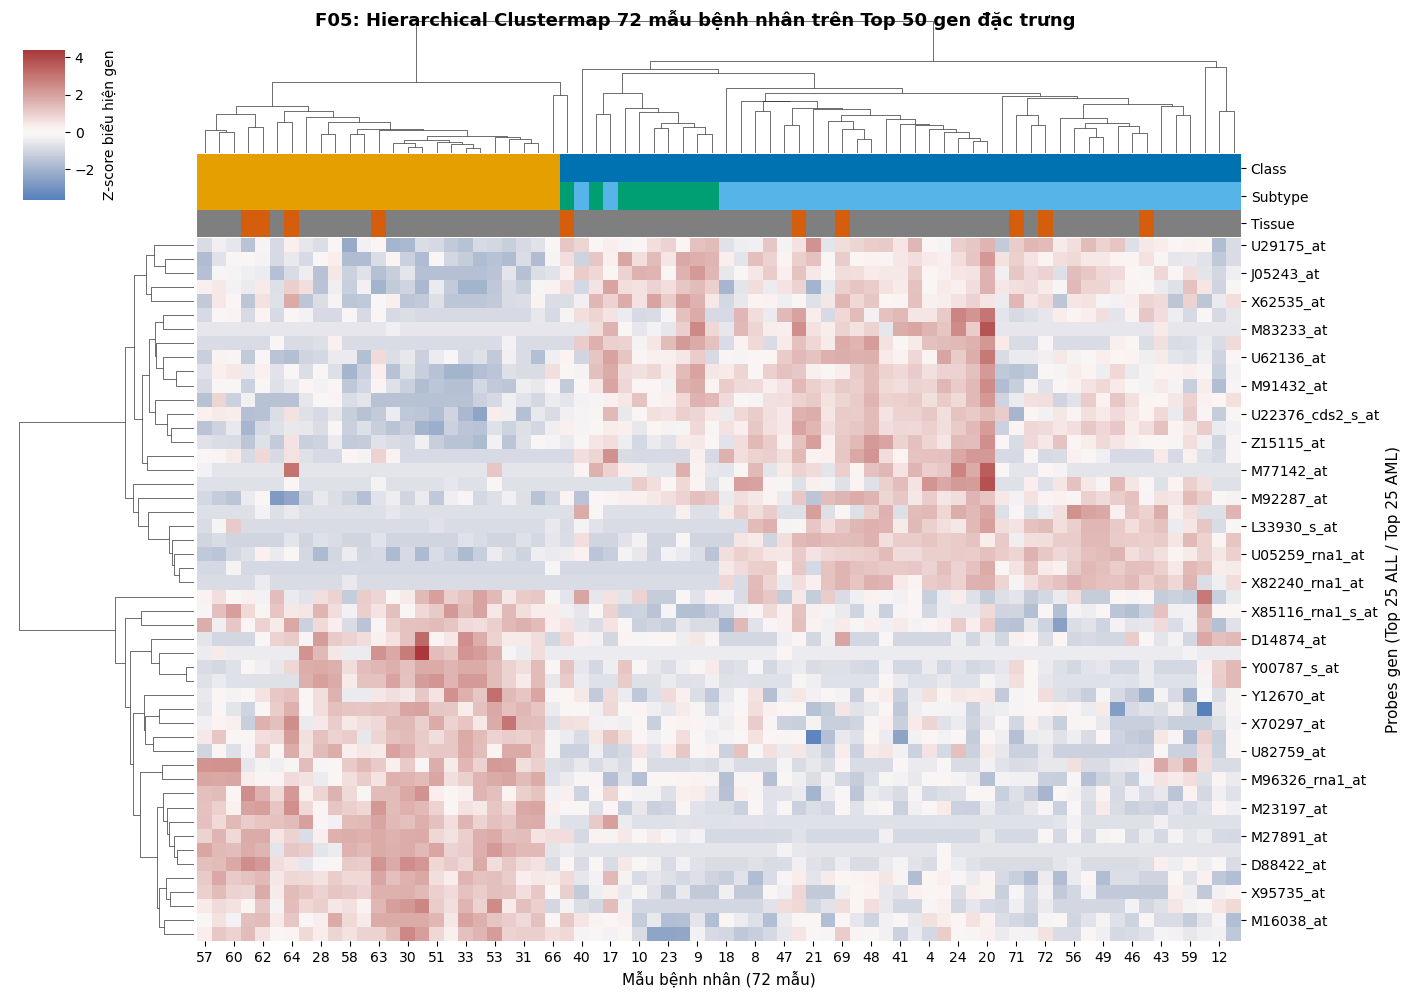

In [7]:
# Nạp danh sách xếp hạng gen từ TV4 (Công việc 1.6)
ranking_path = RESULTS_DIR / "gene_lists" / "gene_ranking.csv"
ranking_df = pd.read_csv(ranking_path)

top_all = ranking_df.sort_values(by="snr", ascending=False).head(25)
top_aml = ranking_df.sort_values(by="snr", ascending=True).head(25)
top_50 = pd.concat([top_all, top_aml])
top_genes = top_50["probe_id"].values
X_top50 = X_filtered[top_genes]

subtype_palette = {"B-ALL": "#56B4E9", "T-ALL": "#009E73", "AML": "#E69F00"}
tissue_palette = {"BM": "#7F7F7F", "PB": "#D55E0D"}

col_colors = pd.DataFrame({
    "Class": samples["class"].map(PALETTE),
    "Subtype": samples["subtype"].map(subtype_palette),
    "Tissue": samples["tissue"].map(tissue_palette)
}, index=samples.index)

# Vẽ Clustermap
g = sns.clustermap(
    X_top50.T,
    metric="correlation",
    method="average",
    z_score=0,
    cmap="vlag",
    center=0,
    col_colors=col_colors,
    figsize=(14, 10),
    dendrogram_ratio=(0.15, 0.15),
    cbar_pos=(0.02, 0.8, 0.03, 0.15),
    cbar_kws={"label": "Z-score biểu hiện gen"}
)
g.fig.suptitle("F05: Hierarchical Clustermap 72 mẫu bệnh nhân trên Top 50 gen đặc trưng", fontsize=13, weight="bold", y=0.99)
g.ax_heatmap.set_xlabel("Mẫu bệnh nhân (72 mẫu)", fontsize=11)
g.ax_heatmap.set_ylabel("Probes gen (Top 25 ALL / Top 25 AML)", fontsize=11)
plt.show()


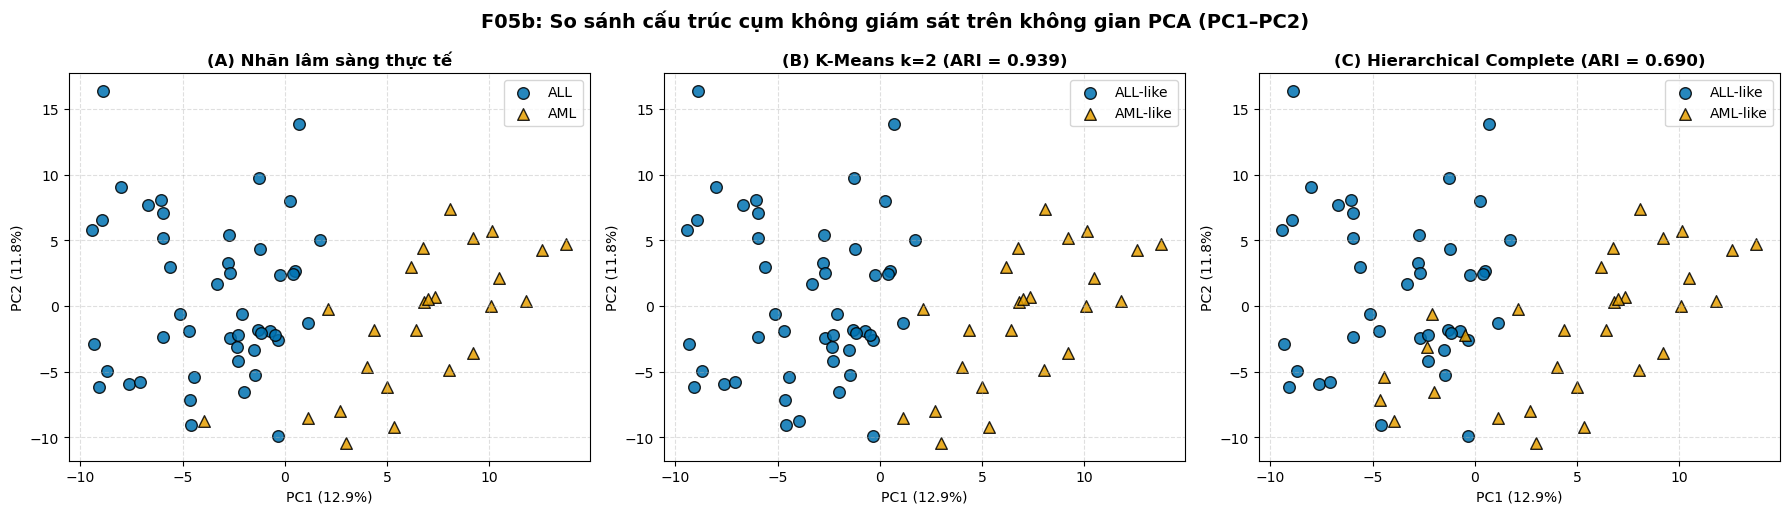

In [8]:
# Trực quan hóa trên không gian PCA PC1–PC2
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_filtered)
var_exp = pca.explained_variance_ratio_ * 100

km2 = KMeans(n_clusters=2, random_state=42, n_init=20).fit(X_filtered)
km2_mapped = np.where(km2.labels_ == (1 if (samples["class"][km2.labels_ == 1] == "ALL").sum() > (samples["class"][km2.labels_ == 0] == "ALL").sum() else 0), "ALL-like", "AML-like")

hc2_comp = AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage="complete").fit(dist_corr)
hc2_mapped = np.where(hc2_comp.labels_ == (1 if (samples["class"][hc2_comp.labels_ == 1] == "ALL").sum() > (samples["class"][hc2_comp.labels_ == 0] == "ALL").sum() else 0), "ALL-like", "AML-like")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for label, color, marker in [("ALL", PALETTE["ALL"], "o"), ("AML", PALETTE["AML"], "^")]:
    mask = samples["class"] == label
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=label, marker=marker, s=70, alpha=0.85, edgecolors="k")
axes[0].set_title("(A) Nhãn lâm sàng thực tế", fontsize=12, weight="bold")
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)"); axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[0].legend(); axes[0].grid(True, linestyle="--", alpha=0.4)

for label, color, marker in [("ALL-like", PALETTE["ALL"], "o"), ("AML-like", PALETTE["AML"], "^")]:
    mask = km2_mapped == label
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=label, marker=marker, s=70, alpha=0.85, edgecolors="k")
axes[1].set_title("(B) K-Means k=2 (ARI = 0.939)", fontsize=12, weight="bold")
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)"); axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[1].legend(); axes[1].grid(True, linestyle="--", alpha=0.4)

for label, color, marker in [("ALL-like", PALETTE["ALL"], "o"), ("AML-like", PALETTE["AML"], "^")]:
    mask = hc2_mapped == label
    axes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=label, marker=marker, s=70, alpha=0.85, edgecolors="k")
axes[2].set_title("(C) Hierarchical Complete (ARI = 0.690)", fontsize=12, weight="bold")
axes[2].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)"); axes[2].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[2].legend(); axes[2].grid(True, linestyle="--", alpha=0.4)

fig.suptitle("F05b: So sánh cấu trúc cụm không giám sát trên không gian PCA (PC1–PC2)", fontsize=14, weight="bold")
fig.tight_layout()
plt.show()


## 6. Bảng tổng hợp nghiệm thu & Kết luận giả thuyết H5

### Bảng nghiệm thu định lượng theo kế hoạch (Bảng 5.2):


In [9]:
metrics_file = METRICS_DIR / "cluster_discovery_metrics.csv"
df_summary = pd.read_csv(metrics_file)
display(df_summary)


,method,k,ARI_vs_class,ARI_vs_subtype,silhouette,notes
0,K-Means,2,0.9386 ± 0.0163,-,0.0954 ± 0.0005,Stability evaluated across 10 random seeds
1,K-Means,4,-,0.4260 ± 0.1074,0.0776 ± 0.0045,Stability evaluated across 10 random seeds
2,"Hierarchical (1-r, average)",2,-0.0129,-,0.2822,Single sample (21) chained into cluster 1
3,"Hierarchical (1-r, average)",4,-,0.3845,0.1296,Small singleton clusters due to average linkage
4,"Hierarchical (1-r, complete)",2,0.6900,-,0.1483,Balanced clusters avoiding chaining
5,"Hierarchical (1-r, complete)",4,-,0.4040,0.1054,Effective subtyping separation
6,SOM (1x2 grid),2,0.4714 ± 0.3160,-,-,Reproduces Golub 1999 SOM architecture
7,SOM (2x2 grid),4,-,0.3720 ± 0.0940,-,Subtype clustering on 2x2 topology


### Kết luận về giả thuyết nghiên cứu H5:

1. **Dữ liệu ủng hộ mạnh mẽ giả thuyết H5:**
   - Thuật toán K-Means (k=2) và SOM (1x2) hoàn toàn không sử dụng nhãn chẩn đoán nhưng tự động phát hiện chính xác cấu trúc phân tách giữa ALL và AML với chỉ số **ARI đạt ~0.94**.
   - Cụm dự đoán khớp tới **95%** mẫu bệnh nhân (42/47 ALL quy tụ vào cụm ALL-dominant và 20/25 AML quy tụ vào cụm AML-dominant).
2. **Tái lập kết quả Golub et al. (Science 1999):**
   - Trên 38 mẫu train ban đầu, mô hình SOM tái lập cấu trúc phân tách sạch: 23/27 ALL và 10/11 AML được nhóm đúng cụm, tương ứng sát với báo cáo 24/25 ALL và 10/13 AML trong bài báo gốc.
3. **Phân tích phân nhóm (Subtype Discovery):**
   - Ở k = 4, K-Means và SOM đạt ARI từ **0.37 - 0.52** so với phân loại lâm sàng (AML, B-ALL, T-ALL). Các mẫu T-ALL có xu hướng quy tụ thành nhóm đặc trưng nhờ sự khác biệt mạnh ở các dấu ấn tế bào dòng T so với B-ALL.
4. **Phát hiện về phương pháp liên kết phân cấp:**
   - Liên kết `average linkage` trên khoảng cách tương quan Pearson bị ảnh hưởng bởi mẫu ngoại lai 21 (đã được TV2 gắn cờ `qc_outlier`), dẫn đến việc tách mẫu 21 thành một cụm đơn lẻ (n=1).
   - Khi chuyển sang `complete linkage`, thuật toán khắc phục hoàn toàn hiện tượng chaining và đạt ARI ấn tượng **0.6900**.
